# 06｜GeoPandas 與 TDX 入門：座標決定位置

**115-1 地理資訊系統運用程式｜W6（10/22）**

前五週的 YouBike 資料，行政區是資料裡寫好的 `sarea` 欄位。從這週開始，我們改用**座標**自己判斷每個站點在哪一區。本週的重點是：

> **同一組數字，換一個座標參考系統（CRS），就是地球上完全不同的位置。** agent 寫的空間連接很少報錯，但 CRS 沒對齊時，它會安靜地回傳 0 筆；分組計數時，沒有站點的鄉鎮也會安靜地消失。

| Part | 內容 |
|---|---|
| A | GeoDataFrame 與檔案格式：讀鄉鎮市區界 |
| B | CRS：用數值範圍判斷、`set_crs` 與 `to_crs`、面積要在投影座標下算 |
| C | TDX：金鑰放 Colab Secrets、token 快取、一次取得整個縣市、存快照 |
| D | 站點 → GeoDataFrame → 空間連接（`sjoin`） |
| E | 計數與標準化：沒有站點的鄉鎮也要算 0 |
| F | 面量圖、`explore()` 疊圖檢查、存成 GPKG |
| G | 陷阱：API 的「縣市」不等於站點所在的縣市 |

**課前準備：**

1. 從新雲端學院下載 `W6_課堂資料.zip`，解壓縮後，把 `Taiwan_boundaries` 與 `tdx_station_20261012` 兩個資料夾上傳到雲端硬碟的 `115-1_GISprog/data/raw/`。
2. 到 Colab 左側的 🔑（Secrets）新增兩個密鑰：`TDX_CLIENT_ID`、`TDX_CLIENT_SECRET`，並打開「Notebook access」。TDX 審核還沒通過的同學，Part C 會自動改讀老師的備援快照。

標示 **【練習】** 的儲存格請自己動手完成。

## 0. 路徑與中文字型

沿用 `00_Colab環境設定範本.ipynb` 的兩個儲存格。本週多了三個路徑：鄉鎮市區界、老師的備援快照，以及你自己從 TDX 抓下來的資料。

In [3]:
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/115-1_GISprog")
else:
    # 備援：本機執行時，notebook 位於 115-1_GISprog/notebooks/，上一層就是專案資料夾
    PROJECT_DIR = Path.cwd().parent

RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
OUTPUT_DIR = PROJECT_DIR / "outputs"
FONT_DIR = PROJECT_DIR / "fonts"

TOWN_SHP = RAW_DIR / "Taiwan_boundaries" / "Town" / "Taiwan_town.shp"  # 鄉鎮市區界
BACKUP_DIR = RAW_DIR / "tdx_station_20261012"                          # 老師 10/12 抓的備援快照
TDX_DIR = RAW_DIR / "tdx"                                              # 你自己從 TDX 抓的資料

for p in [TOWN_SHP, BACKUP_DIR]:
    if not p.exists():
        raise FileNotFoundError(f"找不到 {p}，請依課前準備上傳 W6_課堂資料")

print("執行環境：", "Google Colab" if IN_COLAB else "本機")

執行環境： 本機


In [4]:
import urllib.request

import matplotlib.pyplot as plt
from matplotlib import font_manager

FONT_URL = "https://drive.google.com/uc?id=1eGAsTN1HBpJAkeVM57_C7ccp7hbgSz3_&export=download"
FONT_PATH = FONT_DIR / "TaipeiSansTCBeta-Regular.ttf"

if not FONT_PATH.exists():
    FONT_DIR.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(FONT_URL, FONT_PATH)

font_manager.fontManager.addfont(str(FONT_PATH))     # 告訴 Matplotlib：「這個字型檔可以使用」
plt.rcParams["font.family"] = "Taipei Sans TC Beta"  # 指定之後畫圖預設使用這個中文字型
plt.rcParams["axes.unicode_minus"] = False           # 避免負號 − 顯示異常
print("已設定中文字型：", FONT_PATH.name)

已設定中文字型： TaipeiSansTCBeta-Regular.ttf


---

# Part A｜GeoDataFrame 與檔案格式

## A1. 向量資料：幾何＋屬性

向量資料把世界畫成**點、線、面**，每一個圖形再配上一列屬性。GeoPandas 的 **GeoDataFrame** 就是「多了一個 `geometry` 欄位的 DataFrame」：W3 學的篩選、`groupby`、`merge` 全部都能用。

In [5]:
import geopandas as gpd
import pandas as pd

town = gpd.read_file(TOWN_SHP)

print(type(town))
print("筆數：", len(town))
town.head()

c:\Users\s1112\anaconda3\Lib\site-packages\pyogrio\core.py:35: RuntimeWarning: Could not detect GDAL data files.  Set GDAL_DATA environment variable to the correct path.
  _init_gdal_data()


<class 'geopandas.geodataframe.GeoDataFrame'>
筆數： 352


,TOWNID,TOWNCODE,COUNTYNAME,TOWNNAME,TOWNENG,COUNTYID,COUNTYCODE,FULLNAME,CENSUS,geometry
0,V02,10014020,臺東縣,成功鎮,Chenggong Township,V,10014,臺東縣成功鎮,13845,"POLYGON ((2.92e+05 2.57e+06, 2.92e+05 2.57e+06..."
1,T21,10013210,屏東縣,佳冬鄉,Jiadong Township,T,10013,屏東縣佳冬鄉,18905,"POLYGON ((2.06e+05 2.48e+06, 2.06e+05 2.48e+06..."
2,P13,10009130,雲林縣,麥寮鄉,Mailiao Township,P,10009,雲林縣麥寮鄉,46713,"POLYGON ((1.79e+05 2.64e+06, 1.79e+05 2.64e+06..."
3,V11,10014110,臺東縣,綠島鄉,Lvdao Township,V,10014,臺東縣綠島鄉,4079,"MULTIPOLYGON (((3.01e+05 2.51e+06, 3.01e+05 2...."
4,V16,10014160,臺東縣,蘭嶼鄉,Lanyu Township,V,10014,臺東縣蘭嶼鄉,5151,"MULTIPOLYGON (((3.13e+05 2.43e+06, 3.13e+05 2...."


## A2. Shapefile 不是一個檔案

`read_file` 只指定了 `.shp`，但 GeoPandas 同時讀了好幾個同名的檔案。**只上傳 `.shp` 會讀不到資料**，這是 Shapefile 最常見的錯誤。

In [6]:
for p in sorted(TOWN_SHP.parent.glob("Taiwan_town.*")):
    print(f"{p.name:22s} {p.stat().st_size / 1024:10,.1f} KB")

Taiwan_town.cpg               0.0 KB
Taiwan_town.dbf             123.7 KB
Taiwan_town.prj               0.4 KB
Taiwan_town.sbn               3.7 KB
Taiwan_town.sbx               0.4 KB
Taiwan_town.shp          16,251.2 KB
Taiwan_town.shp.xml           6.9 KB
Taiwan_town.shx               2.8 KB
Taiwan_town.xml               7.9 KB


- TOWN_SHP：
這是一個變數，通常是一個 pathlib.Path 物件，代表一個特定的檔案路徑（例如：/Users/data/Taiwan_town.shp）。

- .parent：
取得 TOWN_SHP 這個檔案所在的「父目錄」（也就是包含這個檔案的資料夾路徑）。例如上述路徑的 .parent 就會是 /Users/data/。

- .glob(...)：
這是 Path 物件提供的方法，用來在該資料夾內進行「萬用字元（Wildcard）搜尋」，並回傳所有符合條件的檔案路徑清單。

- "Taiwan_town.*"：
這是傳給 glob 的搜尋條件。* 是萬用字元，代表「任何字元」。因此這段的意思是：尋找主檔名為 Taiwan_town，且副檔名為任何格式的所有檔案。

| 副檔名 | 內容 | 少了會怎樣 |
|---|---|---|
| `.shp` | 幾何（座標） | 沒有圖形 |
| `.shx` | 幾何的索引 | 讀不到 |
| `.dbf` | 屬性表 | 沒有欄位 |
| `.prj` | **座標參考系統（CRS）** | 讀得到，但 `crs` 是 `None` |
| `.cpg` | 文字編碼（這份是 UTF-8） | 中文可能變亂碼 |

## A3. 幾何型態與欄位

In [7]:
town.geom_type.value_counts()

Polygon         345
MultiPolygon      7
Name: count, dtype: int64

**MultiPolygon** 是「一個鄉鎮由好幾塊面組成」，例如頭城鎮包含龜山島。

這份檔案的欄位：`TOWNCODE`（鄉鎮市區代碼）、`COUNTYNAME`、`TOWNNAME`、`FULLNAME`，以及一個沒有說明的 `CENSUS`。

> **鄉鎮名稱在全國會重複**：「東區」有 4 個、「大安區」有 2 個。合併或對照時要用 `TOWNCODE`，或「縣市＋鄉鎮」一起比對。

In [8]:
town["TOWNNAME"].value_counts().head(5)

TOWNNAME
東區     4
北區     3
南區     2
中山區    2
中正區    2
Name: count, dtype: int64

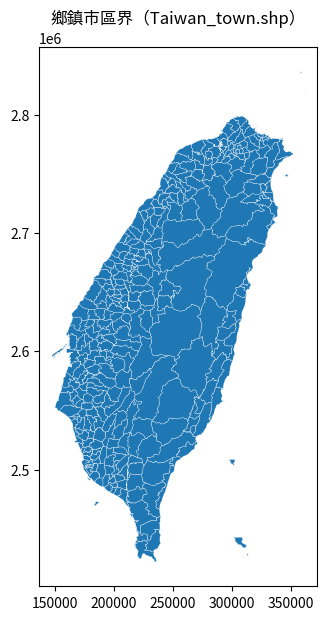

In [9]:
town.plot(figsize=(5, 7), edgecolor="white", linewidth=0.2)
plt.title("鄉鎮市區界（Taiwan_town.shp）")
plt.show()

**【練習 A】** 地圖上少了哪些縣市？用 `town["COUNTYNAME"].unique()` 確認，並想想：如果你的研究範圍包含這些地方，這份檔案還能用嗎？

In [10]:
# TODO：列出這份檔案有哪些縣市、共幾個

## A4. `CENSUS` 是哪一年的人口？

欄位名稱看起來是人口，但檔案沒有說明年份。**先實際檢查，再決定能不能用。** HW1 查過：臺北市 2026 年 7 月的戶籍人口是 2,424,159 人。

In [11]:
town.groupby("COUNTYNAME")["CENSUS"].sum().sort_values(ascending=False).head(6)

COUNTYNAME
新北市    4010657
臺中市    2811729
高雄市    2773786
臺北市    2650154
桃園市    2240328
臺南市    1881730
Name: CENSUS, dtype: int64

臺北市加總約 265 萬，比 2026 年多了 22 萬人，比較接近 2019 年前後的戶籍人口；檔案的中繼資料也寫著邊界來自內政部 2019 年 6 月的版本（`TOWN_MOI_1080617`）。

**結論：** `CENSUS` 可以拿來練習，但如果要算「每萬人站點數」，要在決策表說明這個落差，或改用戶政司的最新資料（HW6 決策點 4）。

---

# Part B｜CRS：同一組數字，不同的位置

## B1. 用數值範圍判斷 CRS

In [12]:
print(town.crs)
print(town.total_bounds)   # [x 最小, y 最小, x 最大, y 最大]

EPSG:3826
[ 147522.21879192 2422004.77310209  361519.68133834 2836375.81627143]


臺灣在三種常見 CRS 下的數值範圍（本島約略值）：

| CRS | 單位 | x 範圍 | y 範圍 | 常見來源 |
|---|---|---|---|---|
| **EPSG:4326**（WGS84 經緯度） | 度 | 119 – 122 | 21.9 – 25.3 | TDX、Google 地圖、GPS |
| **EPSG:3826**（TWD97 二度分帶） | 公尺 | 約 15 萬 – 35 萬 | 約 242 萬 – 280 萬 | 內政部圖資 |
| EPSG:3857（Web Mercator） | 公尺 | 約 1,330 萬 – 1,360 萬 | 約 250 萬 – 290 萬 | 網路地圖底圖 |

`town.total_bounds` 的 x 約 14.7 萬 – 36.2 萬、y 約 242 萬 – 284 萬，單位是公尺，和 `.prj` 寫的 EPSG:3826 一致。

> **用數值範圍判斷 CRS**：看到 120、24 這種數字是經緯度；看到 20 萬、266 萬是 TWD97。agent 說「這是 EPSG:3826」時，要求它**用數值範圍說明依據**。

## B2. `to_crs` 與 `set_crs`：換算 vs. 換標籤

用彰師大進德校區附近的一個點來看。

In [13]:
學校 = gpd.GeoSeries.from_xy([120.5585], [24.0815], crs="EPSG:4326")  # x 是經度、y 是緯度

print("原本（4326）：     ", 學校.iloc[0])
print("to_crs(3826)：     ", 學校.to_crs(3826).iloc[0])
print("set_crs(3826)：    ", 學校.set_crs(3826, allow_override=True).iloc[0])

原本（4326）：      POINT (120.5585 24.0815)
to_crs(3826)：      POINT (205109.1192433848 2664119.638389599)
set_crs(3826)：     POINT (120.5585 24.0815)


- **`to_crs`：真的換算座標。** 經緯度 (120.56, 24.08) → TWD97 (205109, 2664120)，是地球上同一個點。
- **`set_crs`：只換標籤，數字不變。** 它告訴 GeoPandas「這些數字是 EPSG:3826」，於是這個點變成「離原點東 120 公尺、北 24 公尺」，跑到赤道附近的海上。

| 情況 | 用哪個 |
|---|---|
| 資料**沒有** CRS（`crs` 是 `None`），但你知道它是什麼 | `set_crs` |
| 資料**已經有**正確的 CRS，要換成另一種 | `to_crs` |

`set_crs` 在資料已有 CRS 時會報錯，要加 `allow_override=True` 才會執行。**agent 加上 `allow_override=True` 讓錯誤消失時，幾乎都是用錯了。**

## B3. 面積與距離要在投影座標下計算

In [14]:
彰化市 = town[town["FULLNAME"] == "彰化縣彰化市"]

print("EPSG:3826 的面積：", round(彰化市.area.iloc[0] / 1e6, 2), "平方公里")
print("EPSG:4326 的面積：", 彰化市.to_crs(4326).area.iloc[0], "平方『度』")

EPSG:3826 的面積： 65.76 平方公里
EPSG:4326 的面積： 0.005839032684304399 平方『度』


C:\Users\s1112\AppData\Local\Temp\ipykernel_41580\408345153.py:4: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  print("EPSG:4326 的面積：", 彰化市.to_crs(4326).area.iloc[0], "平方『度』")


經緯度下的面積單位是「平方度」，而且同樣一平方度，在不同緯度代表的實際面積不同，**沒有意義**。GeoPandas 會出現 `UserWarning: Geometry is in a geographic CRS`，這個警告不要忽略。

---

# Part C｜TDX Open API

## C1. 先認識 API

- Swagger 線上文件：TDX 官網 → 基礎服務 → 資料服務 → 公共運輸 → **自行車**。本週用 `/v2/Bike/Station/City/{City}`（站點基本資料，靜態）。
- 老師實測（2026-10-12）這支 API 接受 **15 個縣市**：`Taipei`、`NewTaipei`、`Taoyuan`、`Taichung`、`Tainan`、`Kaohsiung`、`Hsinchu`、`HsinchuCounty`、`MiaoliCounty`、`ChanghuaCounty`、`YunlinCounty`、`ChiayiCounty`、`Chiayi`、`PingtungCounty`、`TaitungCounty`。填 `Keelung` 會回傳 400，訊息裡會列出可以用的縣市。
- `ServiceType`：`1` 是 YouBike 1.0、`2` 是 YouBike 2.0、`3` 是 **Moovo**。彰化縣、雲林縣是 Moovo，而且沒有 `BikesCapacity`（車柱數）欄位。

## C2. 金鑰：從 Colab Secrets 讀進環境變數

**金鑰不寫進程式碼。** 讀進環境變數後，同一份程式在 Colab、Codespaces、Render 都能用。不要 `print` 金鑰，只確認「有沒有」。

In [15]:
import os

if IN_COLAB:
    from google.colab import userdata
    for k in ["TDX_CLIENT_ID", "TDX_CLIENT_SECRET"]:
        try:
            os.environ[k] = userdata.get(k)
        except Exception as e:  # 沒設定密鑰，或沒打開 Notebook access
            print(f"讀不到 {k}：{type(e).__name__}")

HAS_KEY = all(os.environ.get(k) for k in ["TDX_CLIENT_ID", "TDX_CLIENT_SECRET"])
print("TDX 金鑰已載入" if HAS_KEY else "沒有 TDX 金鑰，Part C 將改讀老師的備援快照")

沒有 TDX 金鑰，Part C 將改讀老師的備援快照


## C3. 用金鑰換 token，並快取 24 小時

TDX 的流程分兩步：

1. 用 Client ID／Secret 向認證網址換一個 **access token**（效期 24 小時）。
2. 呼叫 API 時，把 token 放在 header 的 `authorization`。

官方要求實作 **token 快取**：效期內重複使用同一個 token，不要每呼叫一次 API 就重新換一次。

In [16]:
import time

import requests

AUTH_URL = "https://tdx.transportdata.tw/auth/realms/TDXConnect/protocol/openid-connect/token"
API_BASE = "https://tdx.transportdata.tw/api/basic"

_token = {"value": None, "expires": 0}
呼叫紀錄 = []   # 每呼叫一次 API 記一筆，最後和 TDX 會員中心的使用統計比對


def get_token():
    """回傳 access token；還沒過期就沿用（token 快取）。"""
    if _token["value"] and time.time() < _token["expires"] - 60:
        return _token["value"]
    r = requests.post(AUTH_URL, data={
        "grant_type": "client_credentials",
        "client_id": os.environ["TDX_CLIENT_ID"],
        "client_secret": os.environ["TDX_CLIENT_SECRET"],
    }, timeout=30)
    r.raise_for_status()
    data = r.json()
    _token["value"] = data["access_token"]
    _token["expires"] = time.time() + data["expires_in"]
    return _token["value"]


def get_json(path, params=None):
    """呼叫 TDX 基礎服務，回傳解析後的 JSON。"""
    headers = {"authorization": f"Bearer {get_token()}", "Accept-Encoding": "gzip"}
    r = requests.get(API_BASE + path, headers=headers,
                     params={"$format": "JSON", **(params or {})}, timeout=30)
    呼叫紀錄.append({"path": path, "status": r.status_code})
    r.raise_for_status()
    return r.json()

## C4. 一次取得整個縣市，存成快照

- **一次呼叫就拿到全縣市的站點**，不要逐站呼叫。
- 抓下來的資料存進 `data/raw/tdx/`。**檔案已經存在就直接讀檔，不再呼叫 API**：重新執行 notebook 不會一直扣點。
- 檔名的日期用**臺灣時間**。Colab 主機的時鐘是 UTC，直接用 `datetime.now()` 會少 8 小時。

In [17]:
import json
from datetime import datetime
from zoneinfo import ZoneInfo

CITY = "ChanghuaCounty"   # 課堂範例：彰化縣。做 HW6 時改成你選的縣市

今天 = datetime.now(ZoneInfo("Asia/Taipei")).strftime("%Y%m%d")
SNAP = TDX_DIR / f"station_{CITY}_{今天}.json"

if SNAP.exists():
    print("讀取今天已存的快照：", SNAP.name)
    data = json.loads(SNAP.read_text(encoding="utf-8"))
elif HAS_KEY:
    data = get_json(f"/v2/Bike/Station/City/{CITY}")
    TDX_DIR.mkdir(parents=True, exist_ok=True)
    SNAP.write_text(json.dumps(data, ensure_ascii=False), encoding="utf-8")
    print("已從 TDX 取得並存檔：", SNAP.name)
else:
    SNAP = BACKUP_DIR / f"station_{CITY}.json"
    print("改讀老師的備援快照：", SNAP.name)
    data = json.loads(SNAP.read_text(encoding="utf-8"))

print("站點數：", len(data))

改讀老師的備援快照： station_ChanghuaCounty.json
站點數： 210


In [18]:
print(json.dumps(data[0], ensure_ascii=False, indent=2))

{
  "StationUID": "CHA128",
  "StationID": "128",
  "AuthorityID": "CHA",
  "StationName": {
    "Zh_tw": "烏溪堤岸",
    "En": "Wuxi Riverside"
  },
  "StationPosition": {
    "PositionLon": 120.541422,
    "PositionLat": 24.11491,
    "GeoHash": "wsm9nvzxd"
  },
  "StationAddress": {
    "Zh_tw": "508彰化縣和美鎮寶廍路國道3號下／近百姓公廟"
  },
  "ServiceType": 3,
  "SrcUpdateTime": "2023-12-15T14:09:52+08:00",
  "UpdateTime": "2026-10-12T15:05:56+08:00"
}


又是 W2 學過的 **list of dict**，而且 dict 裡還有 dict：站名在 `StationName` 裡的 `Zh_tw`，座標在 `StationPosition` 裡的 `PositionLon`（經度）、`PositionLat`（緯度）。

## C5. 額度：agent 最常寫的陷阱

如果請 agent「查每個站點的資料」，它常寫成這樣：

```python
for uid in 站點代碼:                                   # 210 站 → 210 次呼叫
    get_json(f"/v2/Bike/Availability/City/{CITY}",
             {"$filter": f"StationUID eq '{uid}'"})
```

- 基礎會員**每把金鑰每分鐘最多 5 次**，第 6 次就會收到 `429 Too Many Requests`。
- 扣點是「呼叫次數」與「資料量」**合併計算**：基礎服務 1 點 = 1,500 次，加上 150 MB。每月 3 點。
- **正確做法：** 一次取得整個縣市（1 次），需要篩選時在本機用 Pandas，或用 `$filter`、`$select` 減少回傳的資料。

**老師實測（彰化縣站點，2026-10-12）：**

| 寫法 | 傳輸量 |
|---|---|
| 不壓縮 | 74.5 KB |
| `Accept-Encoding: gzip` | **15.5 KB** |
| gzip ＋ `$select=StationUID,StationName,StationPosition` | **11.6 KB** |

**【練習 C】**（會多呼叫 1 次 API；沒有金鑰的同學跳過）用 `$select` 只取 `StationUID`、`StationName`、`StationPosition` 三個欄位，看看第一筆資料剩下哪些欄位。

In [19]:
# TODO：用 get_json 加上 {"$select": "..."} 參數

**說明：** `$select` 只選了三個欄位，回傳的資料卻還多了 `ServiceType`、`SrcUpdateTime`、`UpdateTime`（老師 2026-10-21 在 Colab 確認）。這幾個欄位是 TDX 固定附上的，不是 `$select` 寫錯。

- `ServiceType`：1 = YouBike 1.0、2 = YouBike 2.0、3 = Moovo。彰化縣、雲林縣的站點都是 3。這是每個站點的系統類型，和網址裡的 `/v2/`（API 版本）無關。代碼的意思寫在 Swagger：展開 `GET /v2/Bike/Station/City/{City}` → Responses 的 200 → 切到 Schema。頁面預設是收合的，沒展開前 Ctrl+F 搜不到。
- `SrcUpdateTime`：資料來源最後一次更新這筆站點的時間。彰化縣最早是 2023-12-15，表示站點資料不是即時的。
- `UpdateTime`：TDX 平臺更新這筆資料的時間。

---

# Part D｜站點 → GeoDataFrame → 空間連接

## D1. 攤平巢狀 JSON：`pd.json_normalize`

In [20]:
站點 = pd.json_normalize(data)
print(站點.columns.tolist())

['StationUID', 'StationID', 'AuthorityID', 'ServiceType', 'SrcUpdateTime', 'UpdateTime', 'StationName.Zh_tw', 'StationName.En', 'StationPosition.PositionLon', 'StationPosition.PositionLat', 'StationPosition.GeoHash', 'StationAddress.Zh_tw']


In [21]:
站點 = 站點.rename(columns={
    "StationName.Zh_tw": "站名",
    "StationPosition.PositionLon": "經度",
    "StationPosition.PositionLat": "緯度",
})
站點[["StationUID", "站名", "經度", "緯度", "ServiceType"]].head()

,StationUID,站名,經度,緯度,ServiceType
0,CHA128,烏溪堤岸,120.541422,24.114910,3
1,CHA129,新庄國小,120.533377,24.104085,3
2,CHA130,和美鎮公所,120.495331,24.107907,3
3,CHA131,道東書院,120.493826,24.111165,3
4,CHA132,和東國小,120.501214,24.109163,3


## D2. 建立 GeoDataFrame：`x` 是經度、`y` 是緯度

`points_from_xy(x, y)`：**x 是經度、y 是緯度**。Google 地圖顯示的是「緯度, 經度」，順序相反，agent 也常寫反。

TDX 的座標是經緯度，所以 `crs="EPSG:4326"`。這裡是**資料本來沒有 CRS、由我們告訴 GeoPandas**，相當於 `set_crs`。

In [22]:
站點 = gpd.GeoDataFrame(
    站點,
    geometry=gpd.points_from_xy(站點["經度"], 站點["緯度"]),
    crs="EPSG:4326",
)
print(站點.crs)
print(站點.total_bounds)   # 經度約 120.4–120.7、緯度約 23.8–24.1：在彰化縣

EPSG:4326
[120.359868  23.798356 120.655078  24.130609]


## D3. 兩個圖層的 CRS 不一樣，會怎樣？

鄉鎮市區界是 EPSG:3826，站點是 EPSG:4326。直接做空間連接：

In [23]:
import warnings

with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")
    錯誤 = gpd.sjoin(站點, town, how="inner", predicate="within")

print("連接到的筆數：", len(錯誤))
print("警告：", str(w[0].message).splitlines()[0] if w else "（沒有）")

連接到的筆數： 0
警告： CRS mismatch between the CRS of left geometries and the CRS of right geometries.


**沒有報錯，只有一個警告，結果是 0 筆。** 站點的 (120, 24) 在 TWD97 裡是赤道附近的海上，當然不在任何鄉鎮裡。

正確做法：先把站點 `to_crs` 成和鄉鎮界相同的 CRS。

這段程式碼的主要功能是執行地理空間資料的「空間連接（Spatial Join）」，同時刻意攔截並紀錄執行過程中可能產生的警告訊息（Warnings），而不是讓警告直接洗版終端機。
以下是程式碼的逐行解析：
1. 攔截並紀錄警告訊息

```
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")
```
這是一個 Context Manager（上下文管理器）。record=True 表示將執行過程中發生的所有警告，收集並存放到串列（List）w 裡面。

warnings.simplefilter("always")：強制程式紀錄「所有」警告，即使是預設會被忽略的警告訊息也會被抓出來。


2. 執行空間連接（核心動作）

```
錯誤 = gpd.sjoin(站點, town, how="inner", predicate="within")
```
gpd.sjoin：GeoPandas 的空間連接功能。

站點 與 town：分別代表左側與右側的 GeoDataFrame 資料表。通常 站點 是點位資料（Points），town 是鄉鎮邊界資料（Polygons）。

how="inner"：交集連接。只有成功對應到的資料才會被保留下來（例如：確實落在鄉鎮範圍內的站點）。

predicate="within"：空間條件。這裡代表要找出「完全落在 (within) town 多邊形範圍內」的站點。


3. 印出結果與第一條警告
```
print("連接到的筆數：", len(錯誤))
print("警告：", str(w[0].message).splitlines()[0] if w else "（沒有）")
```
第一行：印出成功執行空間連接後，資料表的總筆數。

第二行：這是一行簡化的條件判斷式。如果 w 裡面有東西（if w，代表有抓到警告），就取出第一個警告 w[0]。

.message 提取警告內容並轉為字串。

.splitlines()[0] 表示只取警告訊息的第一行，讓畫面保持簡潔。

如果沒有警告，則印出「（沒有）」。

為什麼要特別抓這個警告？（常見情境）
在 GeoPandas 中執行 sjoin 時，最常出現的警告就是 CRS mismatch（座標系統不一致）。
如果你的 站點 是經緯度座標（例如 EPSG:4326），而 town 是台灣的平面座標（例如 EPSG:3826），GeoPandas 會跳出警告並自動嘗試處理，但往往會導致計算結果錯誤（例如算出來的點位全部都不在多邊形內）。這段程式碼就是為了優雅地捕捉這個潛在的 CRS 錯誤。

In [24]:
站點_3826 = 站點.to_crs(town.crs)
print(站點_3826.crs)
print(站點_3826.total_bounds)

EPSG:3826
[ 184815.73514386 2632738.04377659  214853.02461879 2669584.47495209]


## D4. `sjoin`：`how` 與 `predicate`

```python
gpd.sjoin(左, 右, how=..., predicate=...)
```

| 參數 | 選項 | 意思 |
|---|---|---|
| `how` | `"inner"`（預設） | 只留有配對到的**左邊**資料 |
| | `"left"` | 左邊**全部保留**，沒配對到的欄位是 `NaN` |
| | `"right"` | 右邊全部保留 |
| `predicate` | `"intersects"`（預設） | 有接觸就算，包含剛好落在界線上 |
| | `"within"` | 左邊**在**右邊裡面 |
| | `"contains"` | 左邊**包含**右邊（方向和 `within` 相反） |

站點在鄉鎮「裡面」，所以左邊放站點、`predicate="within"`、`how="left"`：沒配對到的站點**留下來檢查，不要讓它們消失**。

In [25]:
連接 = gpd.sjoin(
    站點_3826,
    town[["TOWNCODE", "COUNTYNAME", "TOWNNAME", "geometry"]],
    how="left",
    predicate="within",
)

print("站點數：", len(站點_3826), "→ 連接後：", len(連接))
print("沒有配對到鄉鎮的站點：", 連接["TOWNNAME"].isna().sum())
連接["COUNTYNAME"].value_counts(dropna=False)

站點數： 210 → 連接後： 210
沒有配對到鄉鎮的站點： 0


COUNTYNAME
彰化縣    210
Name: count, dtype: int64

每次空間連接後都要檢查三件事：

1. **筆數有沒有變多？** 一個點同時落在兩個面（面有重疊）時，會變成兩列。
2. **有沒有沒配對到的？** 例如座標是 0、站點在海上，或在檔案沒有的離島。
3. **縣市對不對？** API 的 `City` 是「營運單位」，不一定等於站點所在的縣市（Part G）。

---

# Part E｜計數與標準化

## E1. 沒有站點的鄉鎮，去哪了？

In [26]:
各鄉鎮 = 連接["TOWNNAME"].value_counts()
print("有站點的鄉鎮：", len(各鄉鎮))
print("彰化縣的鄉鎮市：", (town["COUNTYNAME"] == "彰化縣").sum())
各鄉鎮.head()

有站點的鄉鎮： 17
彰化縣的鄉鎮市： 26


TOWNNAME
彰化市    48
員林市    39
鹿港鎮    15
田中鎮    13
溪湖鎮    12
Name: count, dtype: int64

`value_counts()` 只會列出「出現過」的鄉鎮。彰化縣有 26 個鄉鎮市，但只有 17 個有站點，**另外 9 個直接消失**。畫地圖時，它們會變成空白，而不是「0 站」。

正確做法：**從鄉鎮界出發**，把站點數對應回去，沒有的補 0。用 `TOWNCODE` 對應，避免同名的鄉鎮。

In [27]:
彰化 = town[town["COUNTYNAME"] == "彰化縣"].copy()
彰化["站點數"] = 彰化["TOWNCODE"].map(連接["TOWNCODE"].value_counts()).fillna(0).astype(int)

print("站點數加總：", 彰化["站點數"].sum(), "（應該等於站點總數", len(連接), "）")
彰化.loc[彰化["站點數"] == 0, ["TOWNNAME", "站點數"]]

站點數加總： 210 （應該等於站點總數 210 ）


,TOWNNAME,站點數
52,線西鄉,0
53,伸港鄉,0
54,秀水鄉,0
56,芬園鄉,0
60,埔鹽鄉,0
65,埤頭鄉,0
66,芳苑鄉,0
67,大城鄉,0
68,竹塘鄉,0


## E2. agent 的另一種寫法：從鄉鎮做 left join，再 `size()`

agent 有時會「從鄉鎮界出發做 left join，再分組計數」，方向是對的，但計數函式選錯就會出錯：

In [28]:
反向 = gpd.sjoin(彰化, 站點_3826[["StationUID", "geometry"]], how="left", predicate="contains")

比較 = pd.DataFrame({
    "size()": 反向.groupby("TOWNNAME").size(),
    "count()": 反向.groupby("TOWNNAME")["StationUID"].count(),
})
比較[比較["count()"] == 0]

,size(),count()
TOWNNAME,,
伸港鄉,1,0
埔鹽鄉,1,0
埤頭鄉,1,0
大城鄉,1,0
秀水鄉,1,0
竹塘鄉,1,0
線西鄉,1,0
芬園鄉,1,0
芳苑鄉,1,0


- left join 會替沒有站點的鄉鎮保留**一列**，那一列的 `StationUID` 是 `NaN`。
- `size()` 數的是**列數**，所以 0 站的鄉鎮會被算成 1 站。
- `count()` 數的是**非缺值的個數**，才是正確的 0。

這種錯誤不會報錯，地圖看起來也很正常，只有**加總和站點總數對不起來**時才會發現。驗證方式：`比較["size()"].sum()` 是多少？

## E3. 標準化：每平方公里站點數

站點數多，可能只是因為鄉鎮比較大。面積要在 **EPSG:3826** 下計算（B3）。

In [29]:
彰化["面積_km2"] = 彰化.area / 1e6
彰化["每平方公里站點數"] = 彰化["站點數"] / 彰化["面積_km2"]

彰化[["TOWNNAME", "站點數", "面積_km2", "每平方公里站點數"]].sort_values(
    "每平方公里站點數", ascending=False).head(8).round(2)

,TOWNNAME,站點數,面積_km2,每平方公里站點數
18,員林市,39,39.41,0.99
50,彰化市,48,65.76,0.73
61,埔心鄉,11,20.98,0.52
342,北斗鎮,8,19.75,0.41
57,溪湖鎮,12,31.03,0.39
5,田中鎮,13,34.45,0.38
62,永靖鄉,7,20.29,0.34
6,社頭鄉,10,35.91,0.28


**【練習 E】** 用 `CENSUS` 算「每萬人站點數」，排序後和「每平方公里站點數」的前 5 名比較。故事有改變嗎？記得 A4 的發現：這份人口是 2019 年前後的資料。

In [30]:
# TODO：新增「每萬人站點數」欄位，列出前 5 名

---

# Part F｜地圖與存檔

## F1. 面量圖（choropleth）

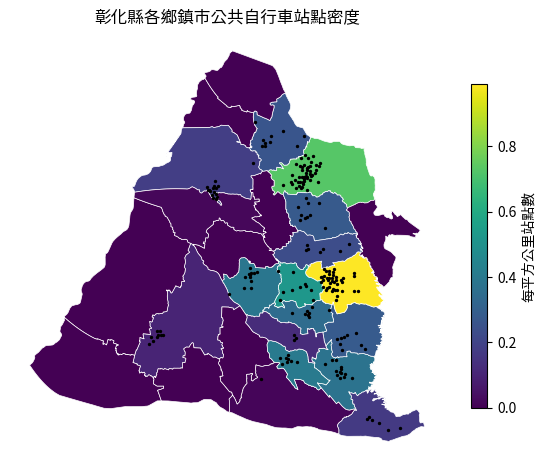

In [31]:
fig, ax = plt.subplots(figsize=(7, 7))
彰化.plot(column="每平方公里站點數", cmap="viridis", legend=True, ax=ax,
          edgecolor="white", linewidth=0.5,
          legend_kwds={"label": "每平方公里站點數", "shrink": 0.6})
站點_3826.plot(ax=ax, color="black", markersize=2)
ax.set_title("彰化縣各鄉鎮市公共自行車站點密度")
ax.set_axis_off()
plt.show()

## F2. `explore()`：疊在底圖上目視檢查

`explore()` 會自動轉成經緯度，疊在網路底圖上。把滑鼠移到鄉鎮上，看看站點是不是真的在那個鄉鎮裡；也可以放大檢查站點有沒有落在河裡、海上。

**底圖改用臺灣通用電子地圖：** `explore()` 預設的 OpenStreetMap 底圖，老師 2026/10/22 在 Colab 實測畫不出來。OSM 的圖磚伺服器由志工維運，會擋掉不符合使用政策的請求，改回傳「Access blocked」的圖片。這裡和 W5 的參考解答一樣，改用內政部國土測繪中心的**臺灣通用電子地圖**：`tiles` 給圖磚網址，`attr` 寫底圖出處（自訂底圖沒寫出處，會出現 `ValueError: Custom tiles must have an attribution`）。注意網址的順序是 `{z}/{y}/{x}`，和 OSM 的 `{z}/{x}/{y}` 相反。

**為什麼不用 W5 的 leafmap？** leafmap 也做得到（例如 `m.add_gdf(...)`），但在 Colab 要先 `%pip install leafmap`。這裡用 `explore()`，是因為它是 GeoDataFrame 自己的方法：一行就好、會自動轉成經緯度，`column`、`tooltip` 直接寫欄名，適合在 notebook 裡快速檢查。要把地圖放進 Solara App、跟篩選元件連動時，再用 W5 的 leafmap。

`explore()` 需要 `mapclassify`，Colab 沒有預先安裝（老師 2025 年實測），先裝一次。每次重新連線都要重裝。

In [32]:
%pip install -q mapclassify

Note: you may need to restart the kernel to use updated packages.


In [33]:
# 臺灣通用電子地圖（內政部國土測繪中心 WMTS）；注意網址是 {z}/{y}/{x}
底圖網址 = "https://wmts.nlsc.gov.tw/wmts/EMAP/default/GoogleMapsCompatible/{z}/{y}/{x}"
底圖出處 = "臺灣通用電子地圖 © 內政部國土測繪中心"

m = 彰化.explore(column="每平方公里站點數", cmap="viridis",
                 tooltip=["TOWNNAME", "站點數", "每平方公里站點數"],
                 style_kwds={"fillOpacity": 0.5},
                 tiles=底圖網址, attr=底圖出處)
站點_3826.explore(m=m, color="red", marker_kwds={"radius": 3},
                  tooltip=["站名", "StationUID"])
m

## F3. 存檔：用 GPKG，不要用 Shapefile

| 格式 | 優點 | 缺點 |
|---|---|---|
| Shapefile | 最老、最多軟體支援 | 多個檔案；**欄位名稱最多 10 bytes**（中文約 3 個字）；單檔 2 GB 上限 |
| GeoJSON | 純文字、網頁地圖常用 | 檔案大；規格要求經緯度（RFC 7946） |
| **GPKG**（GeoPackage） | **單一檔案**、可放多個圖層、中文欄名沒問題 | 純文字編輯器看不懂 |
| GeoParquet | 小、快，適合大量資料 | 較新，部分軟體還不支援 |

In [34]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
GPKG = PROCESSED_DIR / "w6_changhua_station.gpkg"

彰化.to_file(GPKG, layer="town_density", driver="GPKG")
連接.drop(columns="index_right").to_file(GPKG, layer="stations", driver="GPKG")

import pyogrio
print(pyogrio.list_layers(GPKG))

讀回 = gpd.read_file(GPKG, layer="town_density")
print(讀回.crs, len(讀回), 讀回.columns.tolist()[-3:])

[['town_density' 'Polygon']
 ['stations' 'Point']]
EPSG:3826 26 ['面積_km2', '每平方公里站點數', 'geometry']


**Shapefile 的中文欄名會怎樣？** 存一次、再讀回來看看：

In [35]:
SHP = PROCESSED_DIR / "w6_shp_test" / "test.shp"
SHP.parent.mkdir(exist_ok=True)

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    彰化[["TOWNNAME", "每平方公里站點數", "geometry"]].to_file(SHP)

try:
    print(gpd.read_file(SHP).columns.tolist())
except Exception as e:
    print("讀回失敗：", type(e).__name__, str(e)[:80])

SystemError: <class 'bytearray'> returned a result with an exception set

「每平方公里站點數」是 8 個中文字、24 bytes，被截成 10 bytes，**截在一個中文字的中間**，讀回來就出錯（老師本機實測：`UnicodeDecodeError`）。這就是 HW6 要求輸出 GPKG 的原因。

---

# Part G｜陷阱：API 的「縣市」不等於站點所在的縣市

老師用 10/12 的備援快照，把 15 個縣市的站點都和鄉鎮界做了空間連接。新竹市有 7 個站點**不在新竹市**：

In [ ]:
with open(BACKUP_DIR / "station_Hsinchu.json", encoding="utf-8") as f:
    新竹 = pd.json_normalize(json.load(f))

新竹 = gpd.GeoDataFrame(新竹, geometry=gpd.points_from_xy(
    新竹["StationPosition.PositionLon"], 新竹["StationPosition.PositionLat"]), crs="EPSG:4326").to_crs(3826)
新竹連接 = gpd.sjoin(新竹, town[["COUNTYNAME", "TOWNNAME", "geometry"]], how="left", predicate="within")

print(新竹連接["COUNTYNAME"].value_counts(dropna=False))
新竹連接.loc[新竹連接["COUNTYNAME"] != "新竹市", ["StationName.Zh_tw", "COUNTYNAME", "TOWNNAME"]]

這 7 站都在**新竹科學園區**。園區橫跨新竹市與新竹縣寶山鄉，站點由新竹市的系統營運，但實際位置在新竹縣。

老師的檢查結果（2026-10-12）：

| API 的縣市 | 站點數 | 不在該縣市的站點 |
|---|---|---|
| 新竹市 | 217 | 7 站在新竹縣寶山鄉（竹科） |
| 新北市 | 1,614 | 1 站在臺北市內湖區（忠山市民活動中心） |
| 雲林縣 | 262 | 1 站在嘉義縣六腳鄉（北港觀光大橋） |
| 其他 12 個縣市 | — | 0 |

**要不要把這些站算進去？** 沒有標準答案，要看你的問題：

- 問「新竹市**政府**營運幾個站」→ 算進去。
- 問「新竹市**境內**的站點密度」→ 不算，因為分母是新竹市的面積。

這是 HW6 決策點 3 的一部分：**寫出你的選擇與理由。**

---

## 本次 API 呼叫紀錄

和 TDX 會員中心「資料服務 → 使用統計」比對（統計可能有延遲）。這個數字要寫進筆記表頭的「本次 API 呼叫次數與扣點」。

In [ ]:
print("本次執行呼叫 API：", len(呼叫紀錄), "次（不含換 token）")
pd.DataFrame(呼叫紀錄)